In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
from google.colab import files

In [5]:
os.makedirs('model/face', exist_ok=True)

uploaded_models = files.upload()

for filename in uploaded_models.keys():
    dest = os.path.join('model/face', filename)
    os.rename(filename, dest)
    print(f"Moved '{filename}' -> '{dest}'")

Saving face_detection_yunet_2022mar.onnx to face_detection_yunet_2022mar.onnx
Saving face_recognition_sface_2021dec.onnx to face_recognition_sface_2021dec.onnx
Moved 'face_detection_yunet_2022mar.onnx' -> 'model/face/face_detection_yunet_2022mar.onnx'
Moved 'face_recognition_sface_2021dec.onnx' -> 'model/face/face_recognition_sface_2021dec.onnx'


In [4]:
os.makedirs('images', exist_ok=True)

uploaded_images = files.upload()

for filename in uploaded_images.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    print(f"Moved '{filename}' -> '{dest}'")

Saving akhavan.jpg to akhavan.jpg
Saving alireza-in-workshop.jpg to alireza-in-workshop.jpg
Moved 'akhavan.jpg' -> 'images/akhavan.jpg'
Moved 'alireza-in-workshop.jpg' -> 'images/alireza-in-workshop.jpg'


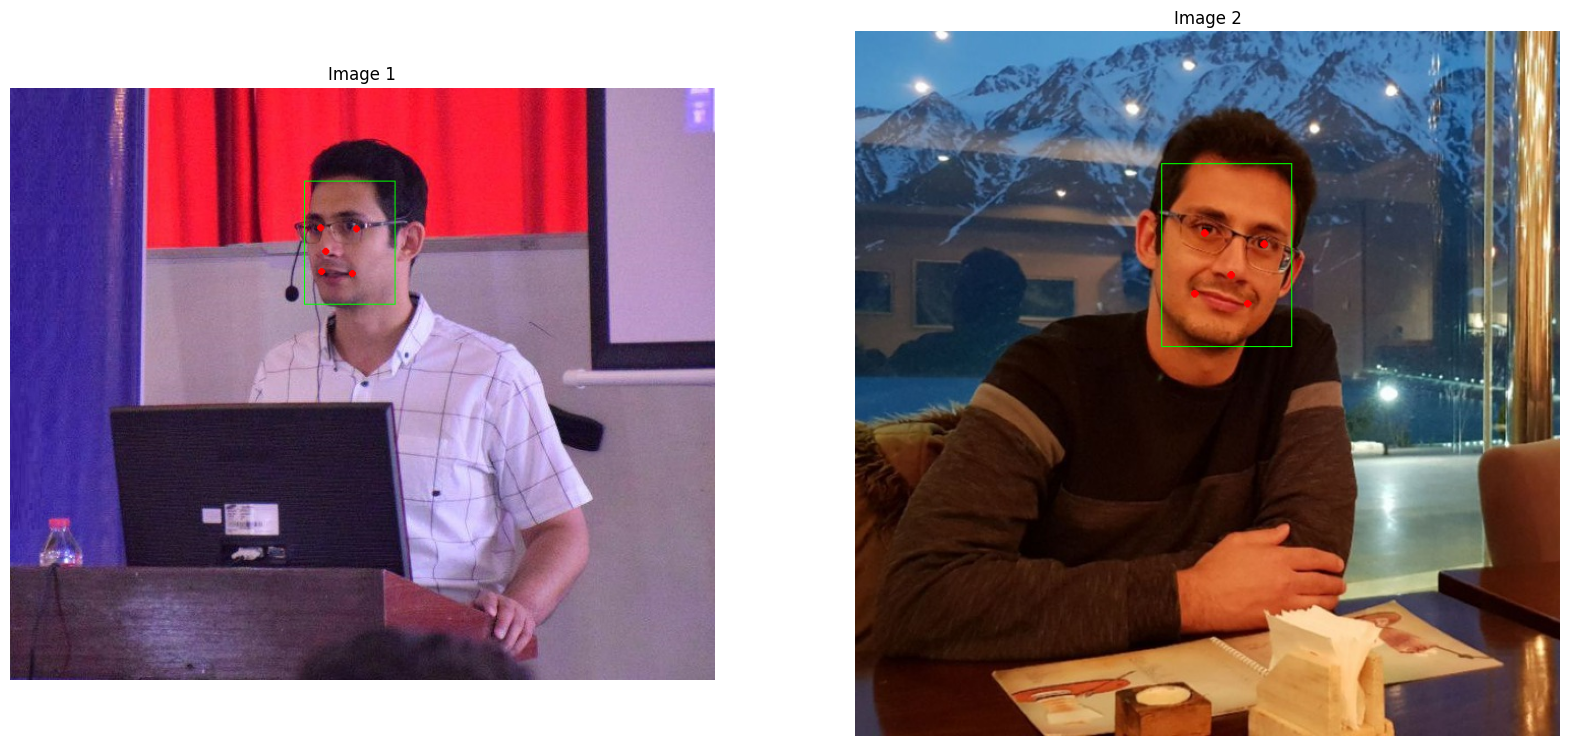

In [10]:
yunet_2023_path = 'model/face/face_detection_yunet_2023mar.onnx'

if not os.path.exists(yunet_2023_path):
    print("Downloading Compatible YuNet 2023 Model...")
    url = 'https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx'
    urllib.request.urlretrieve(url, yunet_2023_path)

model_files = os.listdir('model/face')
ynet_model = next((f for f in model_files if 'yunet_2023' in f.lower()), None) or next((f for f in model_files if 'yunet' in f.lower()), None)
sface_model = next((f for f in model_files if 'sface' in f.lower()), None)

if not ynet_model or not sface_model:
    print("Error: Please Ensure Both YuNet And SFace Model Files Are Uploaded In Cell 2.")
else:
  def visualize(input_img, faces, thickness=2):
      if faces[1] is not None:
        for idx, face in enumerate(faces[1]):
            coords = face[:-1].astype(np.int32)
            cv2.rectangle(input_img, (coords[0], coords[1]), (coords[0]+coords[2], coords[1]+coords[3]), (0, 255, 0))
            cv2.circle(img=input_img, center=(coords[4], coords[5]), radius=2, color=(0, 0, 255), thickness=thickness)
            cv2.circle(img=input_img, center=(coords[6], coords[7]), radius=2, color=(0, 0, 255), thickness=thickness)
            cv2.circle(img=input_img, center=(coords[8], coords[9]), radius=2, color=(0, 0, 255), thickness=thickness)
            cv2.circle(img=input_img, center=(int(coords[10]), int(coords[11])), radius=2, color=(0, 0, 255), thickness=thickness)
            cv2.circle(img=input_img, center=(int(coords[12]), int(coords[13])), radius=2, color=(0, 0, 255), thickness=thickness)

detector = cv2.FaceDetectorYN.create(os.path.join('model/face', ynet_model), "", (320, 320), 0.8, 0.3, 5000)

image_files = [f for f in os.listdir('images') if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

if len(image_files) >= 2:
    img1_path = os.path.join('images', image_files[0])
    img2_path = os.path.join('images', image_files[1])

    img1 = cv2.imread(img1_path)
    image1 = img1.copy()
    h1, w1 = img1.shape[:2]
    detector.setInputSize((w1, h1))
    faces1 = detector.detect(img1)

    img2 = cv2.imread(img2_path)
    image2 = img2.copy()
    h2, w2 = img2.shape[:2]
    detector.setInputSize((w2, h2))
    faces2 = detector.detect(img2)

    if faces1[1] is not None and faces2[1] is not None:
      visualize(image1, faces1)
      visualize(image2, faces2)

      plt.figure(figsize=(20, 10))

      plt.subplot(1, 2, 1)
      plt.imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
      plt.title('Image 1')
      plt.axis('off')

      plt.subplot(1, 2, 2)
      plt.imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
      plt.title('Image 2')
      plt.axis('off')

      plt.show()

Feature Shape: (1, 128)
------------------------------------------------------------
L2 Score: 0.7059187461220944
L2 Similarity Threshold: 1.128
Similarity: same identities
Cosine Score: 0.7669175778131565
Cosine Similarity Threshold: 0.363
Similarity: same identities


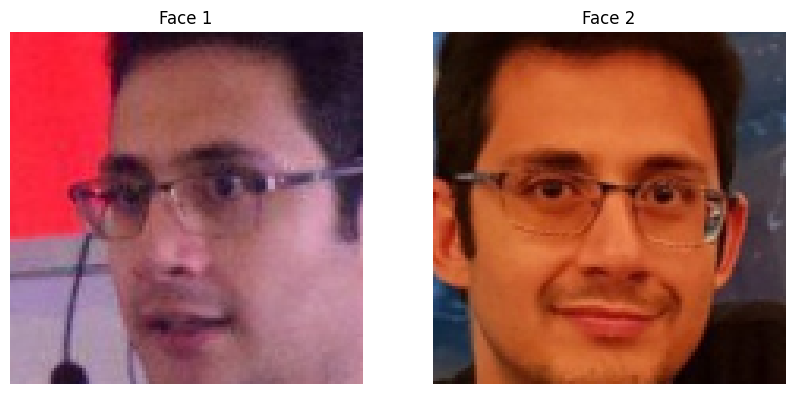

In [14]:
if len(image_files) >= 2 and faces1[1] is not None and faces2[1] is not None:
  recognizer = cv2.FaceRecognizerSF_create(os.path.join('model/face', sface_model), "")

  face1_align = recognizer.alignCrop(img1, faces1[1][0])
  face2_align = recognizer.alignCrop(img2, faces2[1][0])

  face1_features = recognizer.feature(face1_align)
  face2_features = recognizer.feature(face2_align)

  print(f"Feature Shape: {face1_features.shape}")
  print("-" * 60)

  l2_similarity_threshold = 1.128
  l2_score = recognizer.match(face1_features, face2_features, 0)

  msg_l2 = 'different identities'
  if l2_score <= l2_similarity_threshold:
      msg_l2 = 'same identities'

  print(f"L2 Score: {l2_score}")
  print(f"L2 Similarity Threshold: {l2_similarity_threshold}")
  print(f"Similarity: {msg_l2}")

  cosine_similarity_threshold = 0.363
  cosine_score = recognizer.match(face1_features, face2_features, 1)

  msg_cosine = 'different identities'
  if cosine_score >= cosine_similarity_threshold:
      msg_cosine = 'same identities'

  print(f"Cosine Score: {cosine_score}")
  print(f"Cosine Similarity Threshold: {cosine_similarity_threshold}")
  print(f"Similarity: {msg_cosine}")

  plt.figure(figsize=(10, 5))

  plt.subplot(1, 2, 1)
  plt.imshow(cv2.cvtColor(face1_align, cv2.COLOR_BGR2RGB))
  plt.title('Face 1')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(cv2.cvtColor(face2_align, cv2.COLOR_BGR2RGB))
  plt.title('Face 2')
  plt.axis('off')

  plt.show()